In [2]:
# 1. Delete the corrupted local directory
!rm -rf /content/drive

# 2. Re-import and mount
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score,
                             log_loss, confusion_matrix, classification_report,
                             roc_curve, auc, cohen_kappa_score, matthews_corrcoef)
from sklearn.preprocessing import label_binarize
from sklearn.ensemble import RandomForestClassifier # Strictly for sanity checking

# 1. Define Project Paths (Using your exact structure)
BASE_DIR = "/content/drive/MyDrive/AI_Image_Project" # REPLACE WITH YOUR BASE PATH
FEATURES_DIR = os.path.join(BASE_DIR, "features")
MODELS_DIR = os.path.join(BASE_DIR, "saved_models")
RESULTS_DIR = os.path.join(BASE_DIR, "results")
CONF_DIR = os.path.join(RESULTS_DIR, "confusion_matrices")

os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(CONF_DIR, exist_ok=True)

# 2. Load Features, Labels, and Splits
X = np.load(os.path.join(FEATURES_DIR, "X_combined_500.npy"))
y = np.load(os.path.join(FEATURES_DIR, "y_labels_15k.npy"))

train_idx = np.load(os.path.join(FEATURES_DIR, "train_idx.npy"))
val_idx   = np.load(os.path.join(FEATURES_DIR, "val_idx.npy"))
test_idx  = np.load(os.path.join(FEATURES_DIR, "test_idx.npy"))

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val     = X[val_idx], y[val_idx]
X_test, y_test   = X[test_idx], y[test_idx]

CLASS_NAMES = np.array(["Authentic", "Full AI", "Partial AI"])

# 3. Load pre-computed scaler parameters to prevent data leakage
scaler_path = os.path.join(FEATURES_DIR, "scaler_params.npz")
scaler = np.load(scaler_path)
mu, sigma = scaler["mu"], scaler["sigma"]
epsilon = 1e-8

# Apply Z-Score Normalization strictly using training stats
X_train_norm = (X_train - mu) / (sigma + epsilon)
X_val_norm   = (X_val - mu) / (sigma + epsilon)
X_test_norm  = (X_test - mu) / (sigma + epsilon)

# Set random seed for reproducibility
np.random.seed(42)

In [4]:
class Node:
    def __init__(self, predicted_class, depth):
        self.predicted_class = predicted_class
        self.depth = depth
        self.feature_index = 0
        self.threshold = 0.0
        self.left = None
        self.right = None
        self.is_leaf = True

class DecisionTreeScratch:
    def __init__(self, max_depth=10, min_samples_leaf=1, max_features=None, n_bins=32):
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
        self.max_features = max_features
        self.n_bins = n_bins
        self.tree = None
        self.feature_importances_ = None
        self.n_classes = None

    def fit(self, X, y):
        self.n_classes = len(np.unique(y))
        self.feature_importances_ = np.zeros(X.shape[1])
        self.tree = self._grow_tree(X, y, depth=0)
        return self

    def _gini(self, y):
        m = len(y)
        if m == 0: return 0
        counts = np.bincount(y, minlength=self.n_classes)
        probs = counts / m
        return 1.0 - np.sum(probs ** 2)

    def _grow_tree(self, X, y, depth):
        num_samples, num_features = X.shape
        counts = np.bincount(y, minlength=self.n_classes)
        predicted_class = np.argmax(counts)
        node = Node(predicted_class=predicted_class, depth=depth)

        # Stop criteria
        if depth >= self.max_depth or num_samples < self.min_samples_leaf * 2 or len(np.unique(y)) == 1:
            return node

        # Random feature subset
        feat_idxs = np.random.choice(num_features, self.max_features, replace=False)

        best_gini = float('inf')
        best_split = None

        # Fast split search using binning
        for feat in feat_idxs:
            X_col = X[:, feat]
            # Create quantile-based thresholds to speed up search
            thresholds = np.percentile(X_col, np.linspace(5, 95, self.n_bins))
            thresholds = np.unique(thresholds)

            for threshold in thresholds:
                left_mask = X_col <= threshold
                right_mask = ~left_mask

                if np.sum(left_mask) < self.min_samples_leaf or np.sum(right_mask) < self.min_samples_leaf:
                    continue

                gini_left = self._gini(y[left_mask])
                gini_right = self._gini(y[right_mask])
                n_l, n_r = np.sum(left_mask), np.sum(right_mask)
                gini_mix = (n_l * gini_left + n_r * gini_right) / num_samples

                if gini_mix < best_gini:
                    best_gini = gini_mix
                    best_split = (feat, threshold, left_mask, right_mask)

        if best_split is not None:
            feat, threshold, left_mask, right_mask = best_split
            node.feature_index = feat
            node.threshold = threshold
            node.is_leaf = False

            # Feature importance tracking (impurity decrease)
            parent_gini = self._gini(y)
            self.feature_importances_[feat] += (parent_gini - best_gini) * num_samples

            node.left = self._grow_tree(X[left_mask], y[left_mask], depth + 1)
            node.right = self._grow_tree(X[right_mask], y[right_mask], depth + 1)

        return node

    def _predict_row(self, row, node):
        if node.is_leaf:
            return node.predicted_class
        if row[node.feature_index] <= node.threshold:
            return self._predict_row(row, node.left)
        return self._predict_row(row, node.right)

    def predict(self, X):
        return np.array([self._predict_row(row, self.tree) for row in X])


class RandomForestScratch:
    def __init__(self, n_estimators=100, max_depth=10, min_samples_leaf=1, max_features='sqrt', random_state=42):
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
        self.max_features_str = max_features
        self.random_state = random_state
        self.trees = []
        self.feature_importances_ = None
        self.oob_score_ = None
        self.n_classes = None

    def fit(self, X, y):
        np.random.seed(self.random_state)
        self.n_classes = len(np.unique(y))
        n_samples, n_features = X.shape

        if self.max_features_str == 'sqrt':
            self.max_features = int(np.sqrt(n_features))
        elif self.max_features_str == 'log2':
            self.max_features = int(np.log2(n_features))
        else:
            self.max_features = int(n_features * 0.5)

        self.trees = []
        self.feature_importances_ = np.zeros(n_features)
        oob_predictions = np.zeros((n_samples, self.n_classes))
        oob_counts = np.zeros(n_samples)

        print(f"Training {self.n_estimators} trees...")
        for i in range(self.n_estimators):
            # Bootstrap sampling
            indices = np.random.choice(n_samples, n_samples, replace=True)
            oob_indices = np.setdiff1d(np.arange(n_samples), indices)

            tree = DecisionTreeScratch(max_depth=self.max_depth, min_samples_leaf=self.min_samples_leaf, max_features=self.max_features,n_bins=16)
            tree.fit(X[indices], y[indices])
            self.trees.append(tree)
            self.feature_importances_ += tree.feature_importances_

            # OOB predictions
            if len(oob_indices) > 0:
                preds = tree.predict(X[oob_indices])
                for idx, p in zip(oob_indices, preds):
                    oob_predictions[idx, p] += 1
                    oob_counts[idx] += 1

            if (i + 1) % 10 == 0:
                print(f"Tree {i + 1}/{self.n_estimators} built.")

        # Normalize feature importances
        if np.sum(self.feature_importances_) > 0:
            self.feature_importances_ /= np.sum(self.feature_importances_)

        # Calculate OOB score
        valid_oob = oob_counts > 0
        if np.any(valid_oob):
            oob_final_preds = np.argmax(oob_predictions[valid_oob], axis=1)
            self.oob_score_ = accuracy_score(y[valid_oob], oob_final_preds)

        return self

    def predict_proba(self, X):
        tree_preds = np.array([tree.predict(X) for tree in self.trees]) # Shape: (n_estimators, n_samples)
        probs = np.zeros((X.shape[0], self.n_classes))
        for i in range(X.shape[0]):
            counts = np.bincount(tree_preds[:, i], minlength=self.n_classes)
            probs[i] = counts / self.n_estimators
        return probs

    def predict(self, X):
        probs = self.predict_proba(X)
        return np.argmax(probs, axis=1)

Stratified K-Fold distribution:
Fold 1: 4002 samples | Classes: [1334 1334 1334]
Fold 2: 3999 samples | Classes: [1333 1333 1333]
Fold 3: 3999 samples | Classes: [1333 1333 1333]

Total combinations: 12
Total model fits: 36
Total trees: 360

Existing checkpoint loaded.
Completed combinations: 12

Skipping completed combination 1/12: (10, 'sqrt', 1)

Skipping completed combination 2/12: (10, 'sqrt', 5)

Skipping completed combination 3/12: (10, 'log2', 1)

Skipping completed combination 4/12: (10, 'log2', 5)

Skipping completed combination 5/12: (10, '0.5', 1)

Skipping completed combination 6/12: (10, '0.5', 5)

Skipping completed combination 7/12: (20, 'sqrt', 1)

Skipping completed combination 8/12: (20, 'sqrt', 5)

Skipping completed combination 9/12: (20, 'log2', 1)

Skipping completed combination 10/12: (20, 'log2', 5)

Skipping completed combination 11/12: (20, '0.5', 1)

Skipping completed combination 12/12: (20, '0.5', 5)

COARSE GRID SEARCH COMPLETED

Best Parameters:
{'max_de

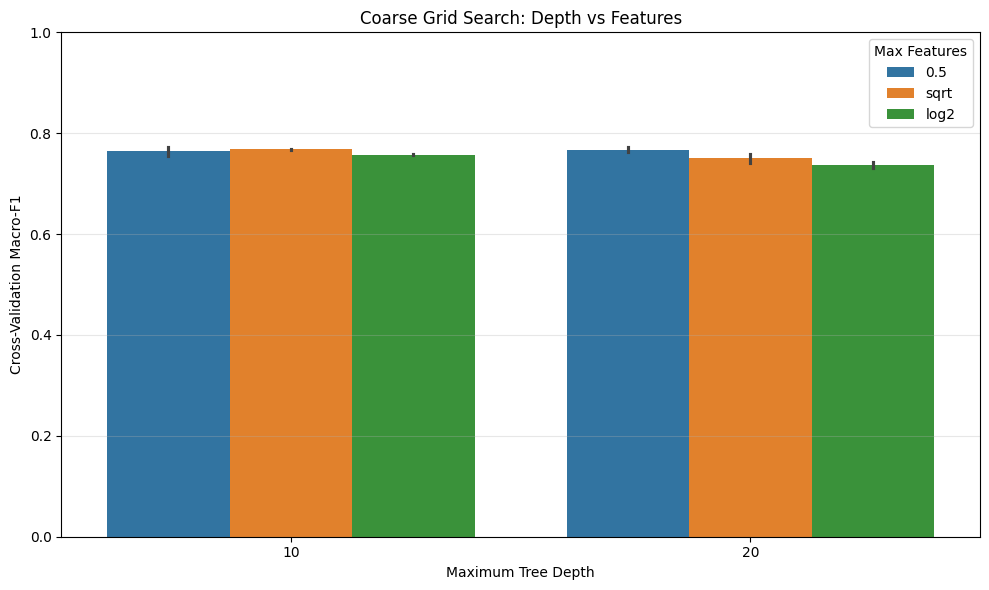


Results saved: /content/drive/MyDrive/AI_Image_Project/results/coarse_grid_results.csv


In [5]:

# ============================================================
# COARSE GRID SEARCH - RANDOM FOREST FROM SCRATCH
# ============================================================

from itertools import product

N_ESTIMATORS = 10
N_FOLDS = 3
RANDOM_SEED = 42

# 1. Define hyperparameter grid
coarse_grid = {
    'max_depth': [10, 20],
    'max_features': ['sqrt', 'log2', '0.5'],
    'min_samples_leaf': [1, 5]
}

# 2. Checkpoint location
CHECKPOINT_PATH = os.path.join(
    RESULTS_DIR, "coarse_grid_results.csv"
)

# 3. Stratified K-Fold generator
def stratified_k_fold(y, k=3, random_state=42):

    rng = np.random.default_rng(random_state)
    indices = np.arange(len(y))
    folds = [[] for _ in range(k)]

    for class_label in np.unique(y):
        class_indices = indices[y == class_label]
        rng.shuffle(class_indices)

        splits = np.array_split(class_indices, k)

        for i in range(k):
            folds[i].extend(splits[i])

    return [np.array(fold, dtype=int) for fold in folds]


# 4. Generate folds
folds = stratified_k_fold(
    y_train,
    k=N_FOLDS,
    random_state=RANDOM_SEED
)

print("Stratified K-Fold distribution:")

for i, fold in enumerate(folds):
    print(
        f"Fold {i+1}: {len(fold)} samples | "
        f"Classes: {np.bincount(y_train[fold])}"
    )


# 5. Generate all combinations
all_combinations = list(product(
    coarse_grid['max_depth'],
    coarse_grid['max_features'],
    coarse_grid['min_samples_leaf']
))

print("\nTotal combinations:", len(all_combinations))
print("Total model fits:", len(all_combinations) * N_FOLDS)
print("Total trees:", len(all_combinations) * N_FOLDS * N_ESTIMATORS)


# 6. Load previous checkpoint if available
if os.path.exists(CHECKPOINT_PATH):

    df_tune = pd.read_csv(CHECKPOINT_PATH)

    completed = {
        (int(row.Depth), str(row.Features), int(row.MinLeaf))
        for _, row in df_tune.iterrows()
    }

    print("\nExisting checkpoint loaded.")
    print("Completed combinations:", len(completed))

else:

    df_tune = pd.DataFrame(
        columns=['Depth', 'Features', 'MinLeaf', 'CV_Macro_F1']
    )

    completed = set()

    print("\nStarting fresh search.")


# 7. Execute Coarse Grid Search
search_start = time.time()

for combo_number, (d, f, m) in enumerate(all_combinations, start=1):

    current_key = (d, f, m)

    if current_key in completed:
        print(
            f"\nSkipping completed combination "
            f"{combo_number}/{len(all_combinations)}: {current_key}"
        )
        continue

    print("\n" + "=" * 60)
    print(f"Combination {combo_number}/{len(all_combinations)}")
    print(f"Depth={d}, Features={f}, MinLeaf={m}")
    print("=" * 60)

    cv_f1_scores = []
    combination_start = time.time()

    for i in range(N_FOLDS):

        fold_start = time.time()

        val_fold_idx = folds[i]

        train_fold_idx = np.hstack([
            folds[j]
            for j in range(N_FOLDS)
            if j != i
        ])

        print(f"\nFold {i+1}/{N_FOLDS}")

        # Train custom Random Forest
        model = RandomForestScratch(
            n_estimators=N_ESTIMATORS,
            max_depth=d,
            max_features=f,
            min_samples_leaf=m,
            random_state=RANDOM_SEED + combo_number * 10 + i
        )

        model.fit(
            X_train_norm[train_fold_idx],
            y_train[train_fold_idx]
        )

        # Validation prediction
        preds = model.predict(
            X_train_norm[val_fold_idx]
        )

        fold_f1 = f1_score(
            y_train[val_fold_idx],
            preds,
            average='macro',
            zero_division=0
        )

        cv_f1_scores.append(fold_f1)

        print(f"Fold Macro-F1: {fold_f1:.4f}")
        print(
            f"Fold time: "
            f"{(time.time()-fold_start)/60:.2f} minutes"
        )

    # Calculate mean CV score
    mean_f1 = np.mean(cv_f1_scores)

    # Store combination result
    new_result = {
        'Depth': d,
        'Features': f,
        'MinLeaf': m,
        'CV_Macro_F1': mean_f1
    }

    df_tune = pd.concat(
        [df_tune, pd.DataFrame([new_result])],
        ignore_index=True
    )

    completed.add(current_key)

    # Save checkpoint after every combination
    df_tune.to_csv(CHECKPOINT_PATH, index=False)

    print("\nCombination completed!")
    print("Fold scores:", cv_f1_scores)
    print(f"Mean CV Macro-F1: {mean_f1:.4f}")
    print(
        f"Combination time: "
        f"{(time.time()-combination_start)/60:.2f} minutes"
    )
    print("Checkpoint saved!")


# 8. Select best parameters
if len(df_tune) != len(all_combinations):
    raise RuntimeError(
        "Grid search incomplete. Saved results are available "
        "in the checkpoint CSV."
    )

df_tune = df_tune.sort_values(
    by='CV_Macro_F1',
    ascending=False
).reset_index(drop=True)

best_params = df_tune.iloc[0]

print("\n" + "=" * 60)
print("COARSE GRID SEARCH COMPLETED")
print("=" * 60)

print("\nBest Parameters:")
print({
    'max_depth': int(best_params['Depth']),
    'max_features': best_params['Features'],
    'min_samples_leaf': int(best_params['MinLeaf']),
    'CV_Macro_F1': round(best_params['CV_Macro_F1'], 4)
})

print("\nAll Results:")
print(df_tune.to_string(index=False))

print(
    f"\nTotal execution time: "
    f"{(time.time()-search_start)/60:.2f} minutes"
)


# 9. Plot results
plt.figure(figsize=(10, 6))

sns.barplot(
    data=df_tune,
    x='Depth',
    y='CV_Macro_F1',
    hue='Features'
)

plt.title("Coarse Grid Search: Depth vs Features")
plt.xlabel("Maximum Tree Depth")
plt.ylabel("Cross-Validation Macro-F1")
plt.ylim(0, 1.0)
plt.grid(axis='y', alpha=0.3)
plt.legend(title="Max Features")
plt.tight_layout()
plt.show()

print("\nResults saved:", CHECKPOINT_PATH)


Training Final Random Forest Model...
Training 100 trees...
Tree 10/100 built.
Tree 20/100 built.
Tree 30/100 built.
Tree 40/100 built.
Tree 50/100 built.
Tree 60/100 built.
Tree 70/100 built.
Tree 80/100 built.
Tree 90/100 built.
Tree 100/100 built.
Final training completed in 9997.22 seconds.
FINAL TEST EVALUATION METRICS
Model               : Random Forest (Scratch)
Accuracy (%)        : 79.67
Macro F1            : 0.7972
Weighted F1         : 0.7972
ROC-AUC (OvR)       : 0.9265
Log Loss            : 0.5007
OOB Score           : 0.7837
Train Time (s)      : 9997.22

              precision    recall  f1-score   support

   Authentic       0.74      0.65      0.69       500
     Full AI       0.97      0.90      0.94       500
  Partial AI       0.70      0.84      0.77       500

    accuracy                           0.80      1500
   macro avg       0.81      0.80      0.80      1500
weighted avg       0.81      0.80      0.80      1500



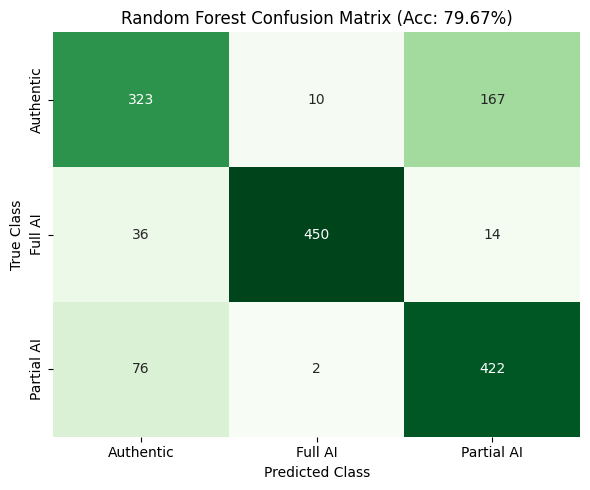

In [7]:

print("Training Final Random Forest Model...")
t0 = time.time()

final_rf = RandomForestScratch(
    n_estimators=100,
    max_depth=int(best_params['Depth']),
    max_features=best_params['Features'],
    min_samples_leaf=int(best_params['MinLeaf']),
    random_state=42
)

final_rf.fit(X_train_norm, y_train)
train_time = time.time() - t0

print(f"Final training completed in {train_time:.2f} seconds.")

# Test Set Evaluation
y_test_prob = final_rf.predict_proba(X_test_norm)
y_test_pred = np.argmax(y_test_prob, axis=1)
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])

metrics_dict = {
    "Model": "Random Forest (Scratch)",
    "Accuracy (%)": round(accuracy_score(y_test, y_test_pred) * 100, 2),
    "Macro F1": round(f1_score(y_test, y_test_pred, average='macro'), 4),
    "Weighted F1": round(f1_score(y_test, y_test_pred, average='weighted'), 4),
    "ROC-AUC (OvR)": round(
        roc_auc_score(y_test_bin, y_test_prob, multi_class='ovr'), 4
    ),
    "Log Loss": round(log_loss(y_test, y_test_prob, labels=[0, 1, 2]), 4),
    "OOB Score": round(final_rf.oob_score_, 4),
    "Train Time (s)": round(train_time, 2)
}

print("=" * 40)
print("FINAL TEST EVALUATION METRICS")
print("=" * 40)

for k, v in metrics_dict.items():
    print(f"{k:<20}: {v}")

print("\n" + classification_report(
    y_test, y_test_pred,
    labels=[0, 1, 2],
    target_names=CLASS_NAMES,
    zero_division=0
))

# Confusion Matrix
cm = confusion_matrix(y_test, y_test_pred, labels=[0, 1, 2])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Greens',
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    cbar=False
)

plt.title(f"Random Forest Confusion Matrix (Acc: {metrics_dict['Accuracy (%)']}%)")
plt.ylabel("True Class")
plt.xlabel("Predicted Class")
plt.tight_layout()

plt.savefig(os.path.join(CONF_DIR, "rf_scratch_cm.png"), dpi=200)
plt.show()


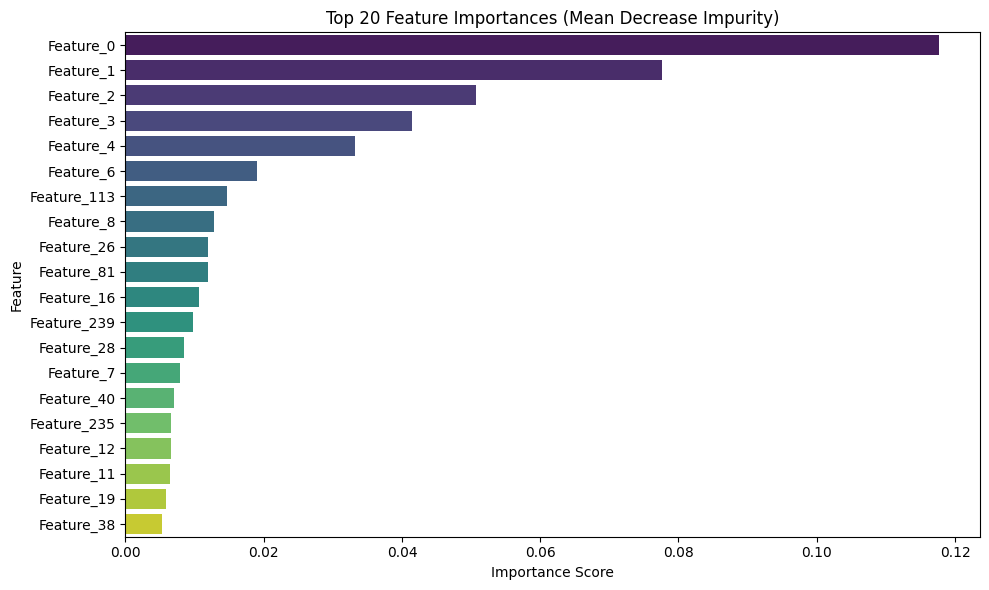

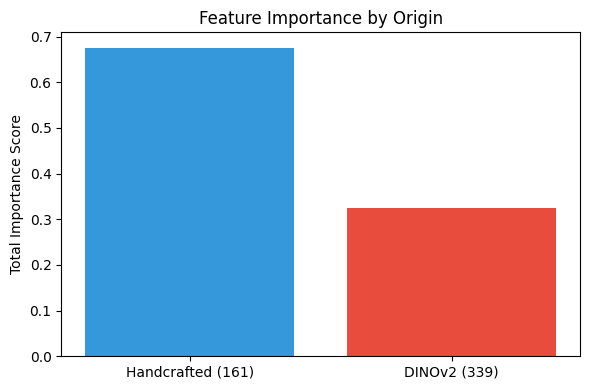

Handcrafted importance: 0.6757
DINOv2 importance: 0.3243


In [8]:

# Extract Top 20 Feature Importances
importances = final_rf.feature_importances_

top_20_idx = np.argsort(importances)[-20:][::-1]
top_20_vals = importances[top_20_idx]

feature_names = [f"Feature_{i}" for i in range(len(importances))]

plt.figure(figsize=(10, 6))
sns.barplot(
    x=top_20_vals,
    y=[feature_names[i] for i in top_20_idx],
    hue=[feature_names[i] for i in top_20_idx],
    palette="viridis",
    legend=False
)

plt.title("Top 20 Feature Importances (Mean Decrease Impurity)")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()

plt.savefig(
    os.path.join(RESULTS_DIR, "rf_top20_feature_importance.png"),
    dpi=200,
    bbox_inches="tight"
)
plt.show()


# Group Feature Importance by Origin
# Assumes features 0-160 are Handcrafted
# and features 161-499 are DINOv2

assert len(importances) == 500, "Expected 500 features. Check feature dimensions."

handcrafted_importance = np.sum(importances[:161])
dino_importance = np.sum(importances[161:])

plt.figure(figsize=(6, 4))

plt.bar(
    ["Handcrafted (161)", "DINOv2 (339)"],
    [handcrafted_importance, dino_importance],
    color=["#3498db", "#e74c3c"]
)

plt.title("Feature Importance by Origin")
plt.ylabel("Total Importance Score")
plt.tight_layout()

plt.savefig(
    os.path.join(RESULTS_DIR, "rf_feature_importance_by_origin.png"),
    dpi=200,
    bbox_inches="tight"
)
plt.show()

print(f"Handcrafted importance: {handcrafted_importance:.4f}")
print(f"DINOv2 importance: {dino_importance:.4f}")


In [9]:

# 1. Save Evaluation Metrics to CSV
csv_path = os.path.join(RESULTS_DIR, "model_comparison_15k.csv")

if os.path.exists(csv_path):
    df_results = pd.read_csv(csv_path)
    df_results = df_results[
        df_results["Model"] != metrics_dict["Model"]
    ]
    df_results = pd.concat(
        [df_results, pd.DataFrame([metrics_dict])],
        ignore_index=True
    )
else:
    df_results = pd.DataFrame([metrics_dict])

df_results.to_csv(csv_path, index=False)
print(f"Metrics saved to: {csv_path}")


# 2. Save Validation and Test Probabilities
# Reuse y_test_prob calculated during final evaluation
y_val_prob = final_rf.predict_proba(X_val_norm)

np.save(
    os.path.join(MODELS_DIR, "rf_scratch_val_probs.npy"),
    y_val_prob
)

np.save(
    os.path.join(MODELS_DIR, "rf_scratch_test_probs.npy"),
    y_test_prob
)

print("Validation and test probabilities saved!")


# 3. Save the Trained Scratch Model
import pickle

model_path = os.path.join(MODELS_DIR, "rf_scratch.pkl")

with open(model_path, "wb") as f:
    pickle.dump(final_rf, f)

print(f"Trained model saved to: {model_path}")


# 4. Optional: Sklearn Sanity Check
RUN_SKLEARN_CHECK = False

if RUN_SKLEARN_CHECK:
    print("\nRunning Sklearn Sanity Check...")

    sk_rf = RandomForestClassifier(
        n_estimators=100,
        max_depth=int(best_params['Depth']),
        random_state=42
    )

    sk_rf.fit(X_train_norm, y_train)
    sk_preds = sk_rf.predict(X_test_norm)

    sk_f1 = f1_score(
        y_test, sk_preds,
        average='macro',
        zero_division=0
    )

    print(
        f"Sklearn Random Forest Macro-F1: {sk_f1:.4f} "
        f"vs Scratch Macro-F1: {metrics_dict['Macro F1']}"
    )

print("\nAll Random Forest results saved successfully!")


Metrics saved to: /content/drive/MyDrive/AI_Image_Project/results/model_comparison_15k.csv
Validation and test probabilities saved!
Trained model saved to: /content/drive/MyDrive/AI_Image_Project/saved_models/rf_scratch.pkl

All Random Forest results saved successfully!


In [10]:
import pickle

model_path = os.path.join(MODELS_DIR, "rf_scratch.pkl")

with open(model_path, "wb") as f:
    pickle.dump(final_rf, f)

print("Final Random Forest model saved successfully!")

Final Random Forest model saved successfully!


In [11]:

# Save dataset split indices
np.save(os.path.join(FEATURES_DIR, "train_idx.npy"), train_idx)
np.save(os.path.join(FEATURES_DIR, "val_idx.npy"), val_idx)
np.save(os.path.join(FEATURES_DIR, "test_idx.npy"), test_idx)

print("Dataset indices saved successfully!")
print("Train indices:", train_idx.shape)
print("Validation indices:", val_idx.shape)
print("Test indices:", test_idx.shape)


Dataset indices saved successfully!
Train indices: (12000,)
Validation indices: (1500,)
Test indices: (1500,)


In [12]:

# Load previously saved indices
train_idx = np.load(os.path.join(FEATURES_DIR, "train_idx.npy"))
val_idx = np.load(os.path.join(FEATURES_DIR, "val_idx.npy"))
test_idx = np.load(os.path.join(FEATURES_DIR, "test_idx.npy"))

# Recreate the same dataset split
X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]

print("Original dataset split restored successfully!")


Original dataset split restored successfully!


In [13]:

import os
import numpy as np
import pandas as pd
import pickle

print("=" * 55)
print("RANDOM FOREST PROJECT - FILE VERIFICATION")
print("=" * 55)

# Expected files
files_to_check = {
    "Trained model": os.path.join(MODELS_DIR, "rf_scratch.pkl"),
    "Validation probabilities": os.path.join(MODELS_DIR, "rf_scratch_val_probs.npy"),
    "Test probabilities": os.path.join(MODELS_DIR, "rf_scratch_test_probs.npy"),
    "Metrics CSV": os.path.join(RESULTS_DIR, "model_comparison_15k.csv"),
    "Confusion matrix": os.path.join(CONF_DIR, "rf_scratch_cm.png"),
    "Top 20 feature plot": os.path.join(RESULTS_DIR, "rf_top20_feature_importance.png"),
    "Feature origin plot": os.path.join(RESULTS_DIR, "rf_feature_importance_by_origin.png"),
    "Train indices": os.path.join(FEATURES_DIR, "train_idx.npy"),
    "Validation indices": os.path.join(FEATURES_DIR, "val_idx.npy"),
    "Test indices": os.path.join(FEATURES_DIR, "test_idx.npy")
}

for name, path in files_to_check.items():
    status = "FOUND" if os.path.isfile(path) else "MISSING"
    print(f"{name:<28}: {status}")

# Check probability arrays
for name in ["rf_scratch_val_probs.npy", "rf_scratch_test_probs.npy"]:
    path = os.path.join(MODELS_DIR, name)
    if os.path.isfile(path):
        arr = np.load(path)
        print(f"{name}: Shape = {arr.shape}")

# Check saved model
model_path = os.path.join(MODELS_DIR, "rf_scratch.pkl")
if os.path.isfile(model_path):
    with open(model_path, "rb") as f:
        saved_model = pickle.load(f)
    print("Model loaded successfully!")
    print("Number of trees:", len(saved_model.trees))

# Check metrics
csv_path = os.path.join(RESULTS_DIR, "model_comparison_15k.csv")
if os.path.isfile(csv_path):
    df = pd.read_csv(csv_path)
    print("\nSaved Model Metrics:")
    display(df)

print("\nVerification completed!")


RANDOM FOREST PROJECT - FILE VERIFICATION
Trained model               : FOUND
Validation probabilities    : FOUND
Test probabilities          : FOUND
Metrics CSV                 : FOUND
Confusion matrix            : FOUND
Top 20 feature plot         : FOUND
Feature origin plot         : FOUND
Train indices               : FOUND
Validation indices          : FOUND
Test indices                : FOUND
rf_scratch_val_probs.npy: Shape = (1500, 3)
rf_scratch_test_probs.npy: Shape = (1500, 3)
Model loaded successfully!
Number of trees: 100

Saved Model Metrics:


,Model,Accuracy (%),Macro F1,Weighted F1,ROC-AUC (OvR),Log Loss,Cohen's Kappa,MCC,Train Time (s),OOB Score
0,Logistic Regression (Scratch),80.80,0.8077,0.8077,0.9304,0.4124,0.712,0.7123,9.86,NaN
1,Linear SVM (Scratch OvR),81.00,0.8084,0.8084,0.9220,0.4503,0.715,0.7165,14.73,NaN
2,RBF-SVM (Scratch RFF OvR),74.40,0.7323,0.7323,0.8978,0.8680,0.616,0.6238,44.52,NaN
3,Random Forest (Scratch),79.67,0.7972,0.7972,0.9265,0.5007,NaN,NaN,9997.22,0.7837



Verification completed!
